# Denoising Diffusion Model on a Ring of Gaussians

This notebook implements a **Denoising Diffusion Probabilistic Model (DDPM)** from first principles in PyTorch on a two-dimensional ring of Gaussians.

### Learning goals
1. Understand the fixed forward noising process and its closed-form marginal.
2. Train a time-conditioned network to predict added noise.
3. Connect noise prediction, denoising, and score estimation.
4. Implement ancestral reverse-diffusion sampling.
5. Visualize how noise is gradually transformed into a multimodal distribution.

The two-dimensional setting makes the entire diffusion process (including vector fields and sample trajectories) directly visible.

## Before you begin

**Prerequisites.** You should be comfortable with Gaussian noise, conditional expectations, Markov chains, neural-network regression, and PyTorch. Basic familiarity with gradients of log densities is helpful for the score interpretation but not required to run the notebook.

> **Notation and orientation**
> - $x_0$ is clean data and $x_t$ is its noisy state. $t=0,\ldots,T-1$ indexes increasing corruption.
> - $\beta_t$ sets added noise, $\alpha_t=1-\beta_t$, and $\bar\alpha_t=\prod_{s\le t}\alpha_s$ is the retained signal.
> - **Forward:** fixed corruption $x_0\rightarrow x_t$. **Reverse:** learned, iterative denoising $x_T\rightarrow\cdots\rightarrow x_0$ using $\epsilon_\theta(x_t,t)$.

## 1. Setup

Only NumPy, Matplotlib, and PyTorch are required. Training uses a GPU automatically when available.

**Runtime:** This toy model trains directly in the notebook. Expect roughly tens of seconds on a recent GPU and up to a few minutes on CPU. The exact time depends on your hardware. Saving the reverse-process GIF adds a short, hardware-dependent rendering step.


In [1]:
import random
import time
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NOTEBOOK_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")
PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (6, 5), "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.12.0+cu130 | device: cuda


## 2. Data: a ring of Gaussians

We use an equally weighted mixture of $K$ isotropic Gaussian components:

$$\mu_k=r[\cos(2\pi k/K),\sin(2\pi k/K)]^\top,\qquad
x_0\mid k\sim\mathcal N(\mu_k,\sigma_{data}^2I).$$

The clean observation is called $x_0$ because diffusion will create progressively noisier variables $x_1,\ldots,x_T$. Component labels are retained only for visualization.

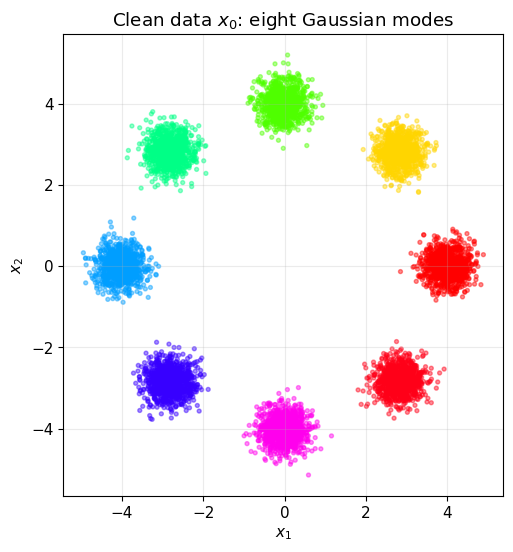

Train shape: (8000, 2)


In [2]:
def sample_ring(n_samples, n_modes=8, radius=4.0, std=0.30, seed=0):
    """Return observations and visualization-only component labels."""
    g = torch.Generator().manual_seed(seed)
    labels = torch.randint(n_modes, (n_samples,), generator=g)
    angles = 2 * torch.pi * labels.float() / n_modes
    centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
    return centers + std * torch.randn(n_samples, 2, generator=g), labels


N_MODES, RADIUS, DATA_STD = 8, 4.0, 0.30
x_train, y_train = sample_ring(8_000, N_MODES, RADIUS, DATA_STD, SEED)
x_test, y_test = sample_ring(2_000, N_MODES, RADIUS, DATA_STD, SEED + 1)
train_loader = DataLoader(
    TensorDataset(x_train),
    batch_size=512,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x_train[:, 0], x_train[:, 1], c=y_train, cmap="hsv", s=8, alpha=0.45)
ax.set(title="Clean data $x_0$: eight Gaussian modes", xlabel="$x_1$", ylabel="$x_2$")
ax.set_aspect("equal")
plt.show()
print("Train shape:", tuple(x_train.shape))

## 3. Forward diffusion process

The forward process gradually adds Gaussian noise according to a fixed variance schedule $\beta_t$:

$$q(x_t\mid x_{t-1})=\mathcal N(\sqrt{1-\beta_t}\,x_{t-1},\beta_tI).$$

Define $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^t\alpha_s$. A crucial Gaussian identity lets us jump directly from clean data to any time step:

$$q(x_t\mid x_0)=\mathcal N(\sqrt{\bar\alpha_t}\,x_0,(1-\bar\alpha_t)I),$$

or equivalently,

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,
\qquad \epsilon\sim\mathcal N(0,I).$$

This closed form makes training efficient: a random $t$ can be sampled without simulating all preceding steps.

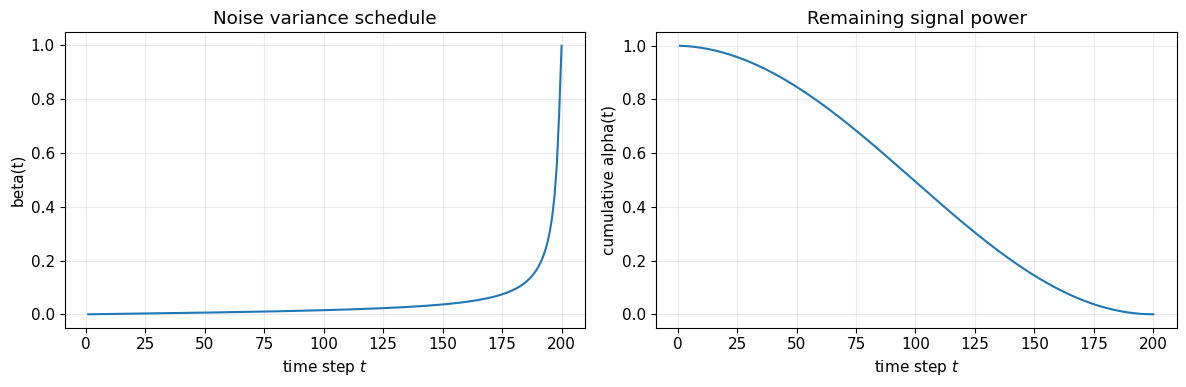

Final cumulative signal power: 6.07e-08


In [3]:
def cosine_beta_schedule(n_steps, offset=0.008):
    """Cosine schedule from Nichol & Dhariwal (2021)."""
    steps = torch.arange(n_steps + 1, dtype=torch.float64)
    f = torch.cos(((steps / n_steps + offset) / (1 + offset)) * torch.pi / 2).square()
    alpha_bar = f / f[0]
    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
    return betas.clamp(1e-5, 0.999).float()


T = 200
betas = cosine_beta_schedule(T).to(DEVICE)
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1 - alpha_bars)


def extract(values, t, target):
    """Gather one schedule value per observation and add broadcast dimensions."""
    return values.gather(0, t).reshape(len(t), *([1] * (target.ndim - 1)))


def q_sample(x0, t, noise=None):
    """Sample x_t directly from q(x_t | x_0)."""
    if noise is None:
        noise = torch.randn_like(x0)
    return (
        extract(sqrt_alpha_bars, t, x0) * x0
        + extract(sqrt_one_minus_alpha_bars, t, x0) * noise
    ), noise


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(torch.arange(1, T + 1).cpu(), betas.cpu())
axes[0].set(xlabel="time step $t$", ylabel="beta(t)", title="Noise variance schedule")
axes[1].plot(torch.arange(1, T + 1).cpu(), alpha_bars.cpu())
axes[1].set(
    xlabel="time step $t$", ylabel="cumulative alpha(t)", title="Remaining signal power"
)
plt.tight_layout()
plt.show()
print(f"Final cumulative signal power: {alpha_bars[-1].item():.2e}")

## 4. Watch the data become noise

At early times, individual modes remain visible. At intermediate times, their identities overlap. At the final time, the distribution is nearly standard normal and carries almost no information about $x_0$.

The forward process is fixed, there are no learned parameters here.

> **Predict before running.** At which displayed time should the eight modes first become difficult to distinguish, and will the cloud's scale necessarily grow without bound? **Commit to a prediction and justify it from $\sqrt{\bar\alpha_t}$ and $\sqrt{1-\bar\alpha_t}$.**

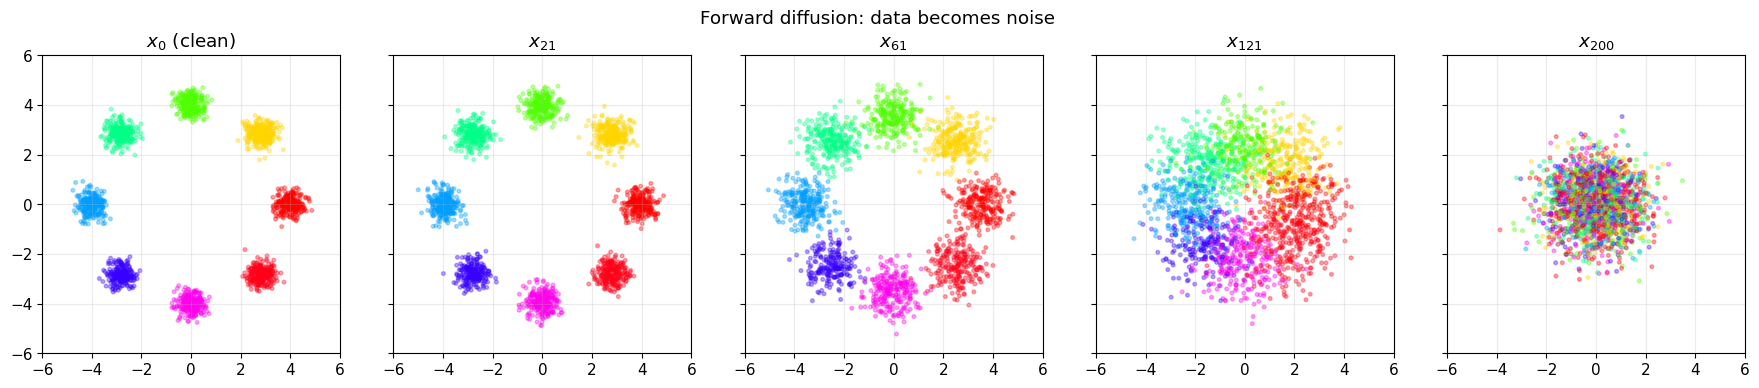

In [4]:
display_times = [0, 20, 60, 120, 199]
fig, axes = plt.subplots(
    1, len(display_times), figsize=(18, 3.7), sharex=True, sharey=True
)
fixed_noise = torch.randn_like(x_test)
for ax, t_value in zip(axes, display_times):
    if t_value == 0:
        points = x_test
        title = "$x_0$ (clean)"
    else:
        t_batch = torch.full((len(x_test),), t_value, dtype=torch.long, device=DEVICE)
        points, _ = q_sample(x_test.to(DEVICE), t_batch, fixed_noise.to(DEVICE))
        points = points.cpu()
        title = f"$x_{{{t_value + 1}}}$"
    ax.scatter(points[:, 0], points[:, 1], c=y_test, cmap="hsv", s=7, alpha=0.35)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
fig.suptitle("Forward diffusion: data becomes noise")
plt.tight_layout()
plt.show()

> **Expected observation / interpretation.** The component identity fades as the signal is attenuated and the Gaussian noise dominates. The process approaches a bounded standard-normal scale rather than diffusing without limit. The schedule controls when local mode structure gives way to global noise.

## 5. Learn to reverse the corruption

The reverse transition $q(x_{t-1}\mid x_t)$ depends on the unknown data distribution. We approximate it with

$$p_\theta(x_{t-1}\mid x_t)=\mathcal N(\mu_\theta(x_t,t),\tilde\beta_t I).$$

A common parameterization asks a neural network $\epsilon_\theta(x_t,t)$ to predict the noise used to create $x_t$. The simplified DDPM objective is

$$\mathcal L_{simple}=\mathbb E_{x_0,t,\epsilon}
\left[\|\epsilon-\epsilon_\theta(x_t,t)\|_2^2\right].$$

The network must know the noise level, so a sinusoidal embedding represents time. This is analogous to positional encodings in Transformers.

In [5]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        assert dim % 2 == 0
        frequencies = torch.exp(
            -np.log(10_000) * torch.arange(dim // 2) / (dim // 2 - 1)
        )
        self.register_buffer("frequencies", frequencies)

    def forward(self, t):
        angles = t.float().unsqueeze(1) * self.frequencies.unsqueeze(0)
        return torch.cat([angles.sin(), angles.cos()], dim=1)


class NoisePredictor(nn.Module):
    def __init__(self, time_dim=32, hidden=128):
        super().__init__()
        self.time_embedding = SinusoidalTimeEmbedding(time_dim)
        self.time_mlp = nn.Sequential(nn.Linear(time_dim, hidden), nn.SiLU())
        self.input_layer = nn.Linear(2, hidden)
        self.blocks = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, hidden)
                )
                for _ in range(3)
            ]
        )
        self.output = nn.Sequential(nn.SiLU(), nn.Linear(hidden, 2))

    def forward(self, x_t, t):
        h = self.input_layer(x_t) + self.time_mlp(self.time_embedding(t))
        for block in self.blocks:
            h = h + block(h)
        return self.output(h)


model = NoisePredictor().to(DEVICE)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

NoisePredictor(
  (time_embedding): SinusoidalTimeEmbedding()
  (time_mlp): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): SiLU()
  )
  (input_layer): Linear(in_features=2, out_features=128, bias=True)
  (blocks): ModuleList(
    (0-2): 3 x Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): SiLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
    )
  )
  (output): Sequential(
    (0): SiLU()
    (1): Linear(in_features=128, out_features=2, bias=True)
  )
)
Parameters: 103,938


## 6. Noise prediction is also score estimation

The score of a density is the vector field $\nabla_{x_t}\log q_t(x_t)$. For Gaussian corruption, the optimal noise predictor and score are related by

$$s_\theta(x_t,t)\approx -\frac{\epsilon_\theta(x_t,t)}{\sqrt{1-\bar\alpha_t}}.$$

Thus, predicting noise teaches the model a direction toward regions of higher noisy-data density at every noise level. The same network also estimates the clean point:

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}
{\sqrt{\bar\alpha_t}}.$$

These are three views of the same learned object: noise predictor, denoiser, and score model.

In [6]:
# Shape and gradient sanity check.
example = x_train[:32].to(DEVICE)
t_example = torch.randint(0, T, (len(example),), device=DEVICE)
x_t, true_noise = q_sample(example, t_example)
predicted_noise = model(x_t, t_example)
loss = F.mse_loss(predicted_noise, true_noise)
loss.backward()
assert predicted_noise.shape == true_noise.shape == (32, 2)
assert torch.isfinite(loss)
assert all(parameter.grad is not None for parameter in model.parameters())
model.zero_grad(set_to_none=True)
print(f"Sanity check passed | initial noise-prediction MSE: {loss.item():.3f}")

Sanity check passed | initial noise-prediction MSE: 1.344


## 7. Train across all noise levels

Each training example uses a uniformly sampled time step. A single network therefore learns a family of denoising problems, ranging from tiny perturbations to almost pure noise.

In [7]:
EPOCHS = 350
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-5)
history = []
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for (x0,) in train_loader:
        x0 = x0.to(DEVICE)
        t = torch.randint(0, T, (len(x0),), device=DEVICE)
        x_t, noise = q_sample(x0, t)
        optimizer.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(x_t, t), noise)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        total_loss += loss.item() * len(x0)
    average = total_loss / len(x_train)
    history.append(average)
    if epoch == 1 or epoch % 50 == 0:
        print(f"epoch {epoch:3d} | noise-prediction MSE {average:.4f}")
print(f"Training time: {time.time() - start:.1f} s")

epoch   1 | noise-prediction MSE 0.9503
epoch  50 | noise-prediction MSE 0.4960
epoch 100 | noise-prediction MSE 0.4775
epoch 150 | noise-prediction MSE 0.4914
epoch 200 | noise-prediction MSE 0.4831
epoch 250 | noise-prediction MSE 0.5036
epoch 300 | noise-prediction MSE 0.4796
epoch 350 | noise-prediction MSE 0.4748
Training time: 21.9 s


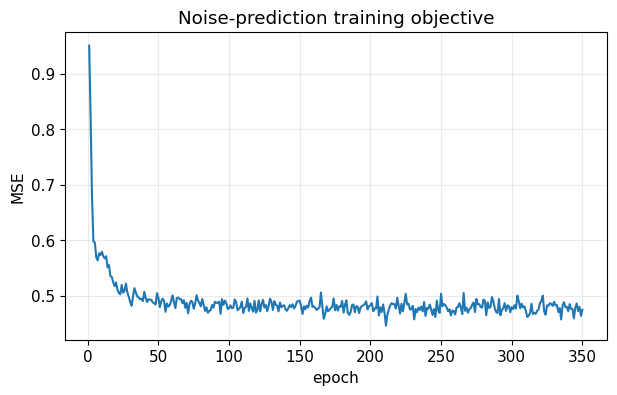

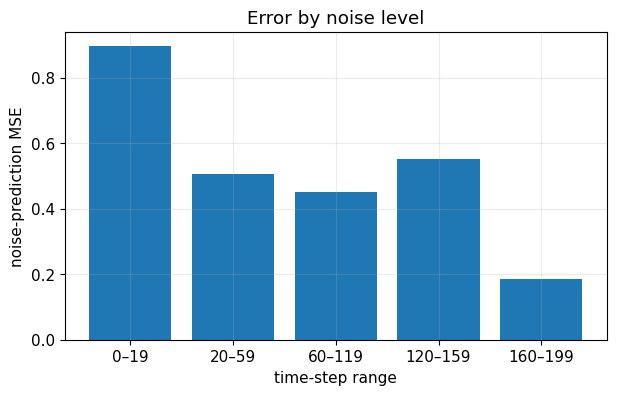

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, EPOCHS + 1), history)
ax.set(xlabel="epoch", ylabel="MSE", title="Noise-prediction training objective")
plt.show()

# Evaluate error separately by noise level; aggregate loss can hide where the task is difficult.
model.eval()
bin_edges = torch.tensor([0, 20, 60, 120, 160, 200], device=DEVICE)
with torch.no_grad():
    repeats = 5
    evaluation_x = x_test.to(DEVICE).repeat(repeats, 1)
    evaluation_t = torch.randint(0, T, (len(evaluation_x),), device=DEVICE)
    evaluation_xt, evaluation_noise = q_sample(evaluation_x, evaluation_t)
    squared_error = (
        (model(evaluation_xt, evaluation_t) - evaluation_noise).square().mean(1)
    )
    binned_mse = []
    for left, right in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (evaluation_t >= left) & (evaluation_t < right)
        binned_mse.append(squared_error[mask].mean().item())

fig, ax = plt.subplots(figsize=(7, 4))
labels = [
    f"{int(a)}–{int(b)-1}" for a, b in zip(bin_edges[:-1].cpu(), bin_edges[1:].cpu())
]
ax.bar(labels, binned_mse)
ax.set(
    xlabel="time-step range",
    ylabel="noise-prediction MSE",
    title="Error by noise level",
)
plt.show()

## 8. Denoising at selected noise levels

For a diagnostic (not the full sampling algorithm) we corrupt held-out points and estimate $x_0$ in one network evaluation. At very late times, recovering a particular original point is impossible because most information has been destroyed. The optimal predictor represents an average consistent with $x_t$.

> **Predict before running.** Will one-step $\hat x_0$ estimates recover each original point equally well at early and late times? **Rank the displayed noise levels and explain what information remains available to a conditional-mean denoiser.**

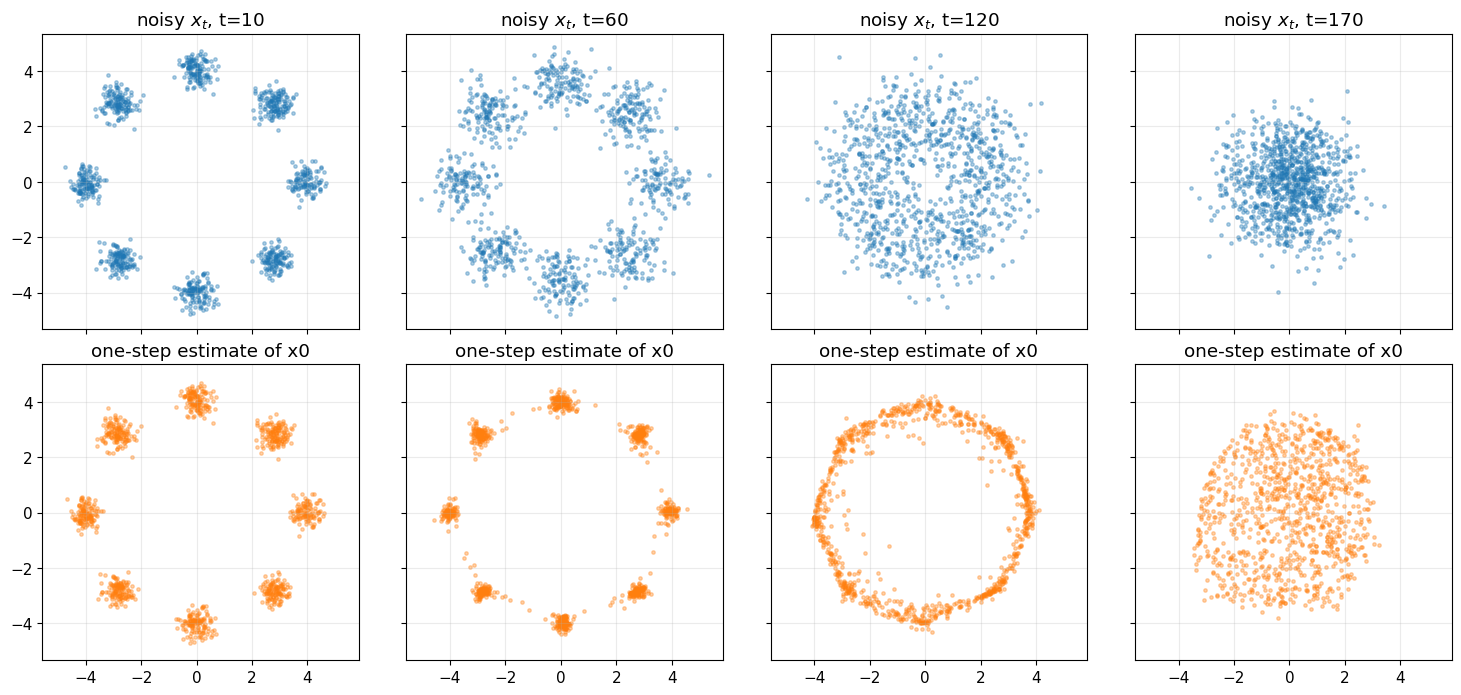

In [9]:
def predict_x0(model, x_t, t):
    predicted_noise = model(x_t, t)
    return (
        x_t - extract(sqrt_one_minus_alpha_bars, t, x_t) * predicted_noise
    ) / extract(sqrt_alpha_bars, t, x_t).clamp_min(1e-5)


selected_times = [10, 60, 120, 170]
subset = x_test[:1000].to(DEVICE)
fig, axes = plt.subplots(
    2, len(selected_times), figsize=(15, 7), sharex=True, sharey=True
)
model.eval()
with torch.no_grad():
    for column, t_value in enumerate(selected_times):
        t_batch = torch.full((len(subset),), t_value, dtype=torch.long, device=DEVICE)
        x_t, _ = q_sample(subset, t_batch)
        estimated_x0 = predict_x0(model, x_t, t_batch)
        axes[0, column].scatter(x_t[:, 0].cpu(), x_t[:, 1].cpu(), s=6, alpha=0.35)
        axes[0, column].set_title(f"noisy $x_t$, t={t_value}")
        axes[1, column].scatter(
            estimated_x0[:, 0].cpu(),
            estimated_x0[:, 1].cpu(),
            s=6,
            alpha=0.35,
            color=PLOT_GENERATED_COLOR,
        )
        axes[1, column].set_title("one-step estimate of x0")
        for row in range(2):
            axes[row, column].set_aspect("equal")
plt.tight_layout()
plt.show()

> **Expected observation / interpretation.** Early noisy points retain enough information for accurate pointwise recovery. At late times, many clean points are plausible for the same $x_t$, so a one-step estimate reflects a conditional average or a broad structural guess. This is why full generation uses many reverse steps rather than one deterministic jump.

## 9. Reverse-diffusion sampling

Starting from $x_T\sim\mathcal N(0,I)$, DDPM ancestral sampling repeatedly applies

$$\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right),$$

$$x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\tilde\beta_t}\,z,
\qquad z\sim\mathcal N(0,I),$$

where $\tilde\beta_t=\beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$. No noise is added in the final step. Unlike training, sampling must traverse all time steps sequentially.

In [10]:
alpha_bars_previous = torch.cat([torch.ones(1, device=DEVICE), alpha_bars[:-1]])
posterior_variance = betas * (1 - alpha_bars_previous) / (1 - alpha_bars)


@torch.no_grad()
def p_sample(model, x_t, t_index):
    """One ancestral reverse step x_t -> x_(t-1)."""
    t = torch.full((len(x_t),), t_index, dtype=torch.long, device=x_t.device)
    predicted_noise = model(x_t, t)
    mean = (
        x_t - betas[t_index] / sqrt_one_minus_alpha_bars[t_index] * predicted_noise
    ) / torch.sqrt(alphas[t_index])
    if t_index == 0:
        return mean
    return mean + torch.sqrt(posterior_variance[t_index]) * torch.randn_like(x_t)


@torch.no_grad()
def sample_ddpm(model, n_samples, save_at=()):
    x = torch.randn(n_samples, 2, device=DEVICE)
    snapshots = {T: x.cpu()}
    for t_index in reversed(range(T)):
        x = p_sample(model, x, t_index)
        remaining = t_index
        if remaining in save_at:
            snapshots[remaining] = x.cpu()
    return x.cpu(), snapshots


model.eval()
generated, reverse_snapshots = sample_ddpm(model, 5_000, save_at=[150, 100, 50, 10, 0])
print("Generated shape:", tuple(generated.shape))

Generated shape: (5000, 2)


## 10. Watch noise become data

The reverse chain begins with isotropic Gaussian noise. The animation keeps the **ground-truth distribution fixed on the left** while the same generated particles evolve **on the right**. Broad structure emerges first and the eight modes sharpen near the end. No component labels or per-particle colors are used.


In [11]:
@torch.no_grad()
def sample_reverse_animation(model, n_samples=2_000, frame_stride=4):
    """Retain evenly spaced states from x_T through x_0 for animation."""
    model.eval()
    x = torch.randn(n_samples, 2, device=DEVICE)
    states = [x.cpu()]
    steps = [T]
    for t_index in reversed(range(T)):
        x = p_sample(model, x, t_index)
        # t_index is the state reached after this transition; retain x_0 explicitly.
        if t_index % frame_stride == 0 or t_index == 0:
            states.append(x.cpu())
            steps.append(t_index)
    return states, steps


animation_states, animation_steps = sample_reverse_animation(
    model, n_samples=2_000, frame_stride=4
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
fig.suptitle("Reverse diffusion: noise becomes data")

axes[0].scatter(
    x_test[:, 0], x_test[:, 1], s=8, alpha=0.35, color=PLOT_REFERENCE_COLOR, edgecolors="none"
)
axes[0].set_title("Ground-truth distribution")

initial_points = animation_states[0]
generated_scatter = axes[1].scatter(
    initial_points[:, 0],
    initial_points[:, 1],
    s=8,
    alpha=0.35,
    color=PLOT_GENERATED_COLOR,
    edgecolors="none",
)
generated_title = axes[1].set_title(f"Generated: $x_{{{animation_steps[0]}}}$ (noise)")

for ax in axes:
    ax.set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-6, 6), ylim=(-6, 6))
    ax.set_aspect("equal")


def update_reverse_animation(frame):
    points = animation_states[frame]
    generated_scatter.set_offsets(points.numpy())
    step = animation_steps[frame]
    generated_title.set_text(
        "Generated: $x_0$ (sample)" if step == 0 else f"Generated: $x_{{{step}}}$"
    )
    return generated_scatter, generated_title


reverse_animation = FuncAnimation(
    fig,
    update_reverse_animation,
    frames=len(animation_states),
    interval=100,
    blit=False,
    repeat=True,
)

GIF_PATH = NOTEBOOK_DIR / "diffusion_ring_reverse.gif"
reverse_animation.save(
    GIF_PATH,
    writer=PillowWriter(fps=10),
    dpi=100,
)
print(f"Saved animation to {GIF_PATH}")

plt.close(fig)  # Avoid a duplicate static figure below the saved animation.
display(Markdown("[Open the saved reverse-diffusion GIF](diffusion_ring_reverse.gif)"))


Saved animation to diffusion_ring_reverse.gif


[Open the saved reverse-diffusion GIF](diffusion_ring_reverse.gif)

## 11. Visualize the learned score field

The score points in the direction of increasing noisy-data log density. Early in the forward process it points sharply toward individual modes. At higher noise levels it describes smoother global structure.

Arrow lengths are normalized in each panel to emphasize direction. The background points show samples from the corresponding forward marginal $q_t(x_t)$.

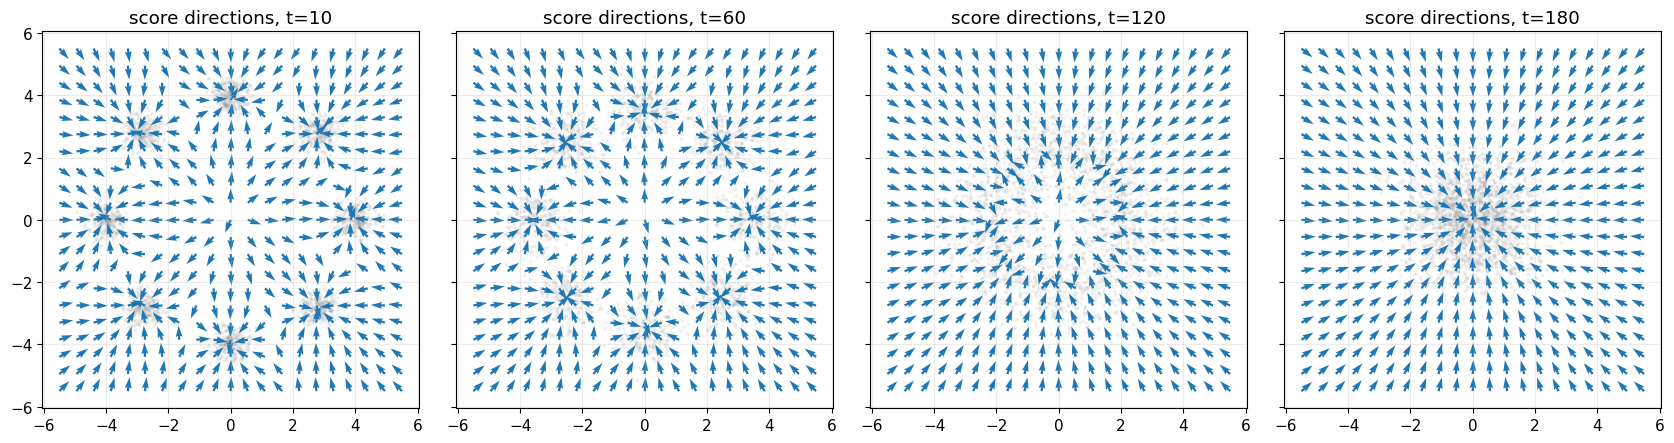

In [12]:
grid_axis = torch.linspace(-5.5, 5.5, 21)
gx, gy = torch.meshgrid(grid_axis, grid_axis, indexing="xy")
score_grid = torch.stack([gx.ravel(), gy.ravel()], dim=1).to(DEVICE)
score_times = [10, 60, 120, 180]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharex=True, sharey=True)
model.eval()
with torch.no_grad():
    for ax, t_value in zip(axes, score_times):
        t_grid = torch.full(
            (len(score_grid),), t_value, dtype=torch.long, device=DEVICE
        )
        score = -model(score_grid, t_grid) / sqrt_one_minus_alpha_bars[t_value]
        score = score / score.norm(dim=1, keepdim=True).clamp_min(1e-6)
        t_data = torch.full((len(x_test),), t_value, dtype=torch.long, device=DEVICE)
        noisy_data, _ = q_sample(x_test.to(DEVICE), t_data)
        ax.scatter(
            noisy_data[:, 0].cpu(),
            noisy_data[:, 1].cpu(),
            s=3,
            alpha=0.08,
            color="gray",
        )
        ax.quiver(
            score_grid[:, 0].cpu(),
            score_grid[:, 1].cpu(),
            score[:, 0].cpu(),
            score[:, 1].cpu(),
            angles="xy",
            scale_units="xy",
            scale=2.2,
            width=0.006,
            color="tab:blue",
        )
        ax.set_title(f"score directions, t={t_value}")
        ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 12. Individual reverse trajectories

Tracking a few particles shows that reverse diffusion is not a one-shot mapping. Each point follows a stochastic path guided by the learned time-dependent score field.

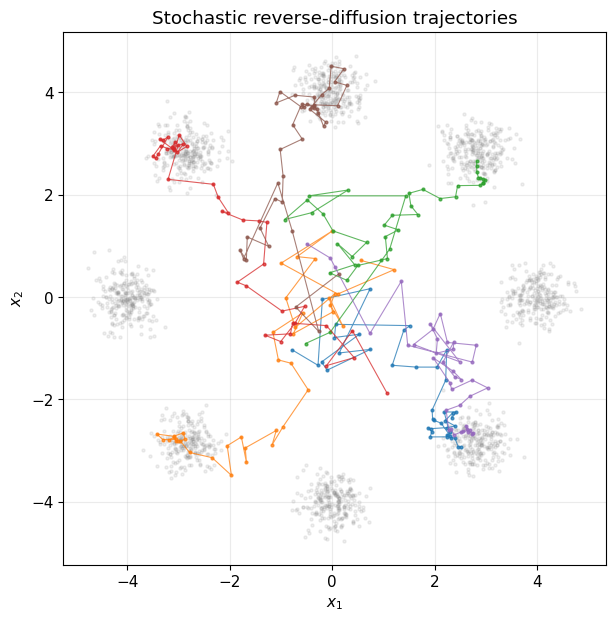

In [16]:
@torch.no_grad()
def sample_trajectories(model, n_particles=6):
    x = torch.randn(n_particles, 2, device=DEVICE)
    trajectory = [x.cpu()]
    for t_index in reversed(range(T)):
        x = p_sample(model, x, t_index)
        if t_index % 5 == 0 or t_index == 0:
            trajectory.append(x.cpu())
    return torch.stack(trajectory, dim=0)


trajectories = sample_trajectories(model)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(x_test[:, 0], x_test[:, 1], s=5, alpha=0.12, color="gray")
for particle in range(trajectories.shape[1]):
    path = trajectories[:, particle]
    ax.plot(path[:, 0], path[:, 1], "o-", markersize=2, linewidth=0.8, alpha=0.75)
ax.set(
    title="Stochastic reverse-diffusion trajectories", xlabel="$x_1$", ylabel="$x_2$"
)
ax.set_aspect("equal")
plt.show()

## 13. Quantitative toy diagnostics

As in the preceding notebooks, we measure nearest-mode frequencies, radial error, and the fraction of samples farther than three data standard deviations from every center. These sample-based diagnostics test both coverage and fidelity.

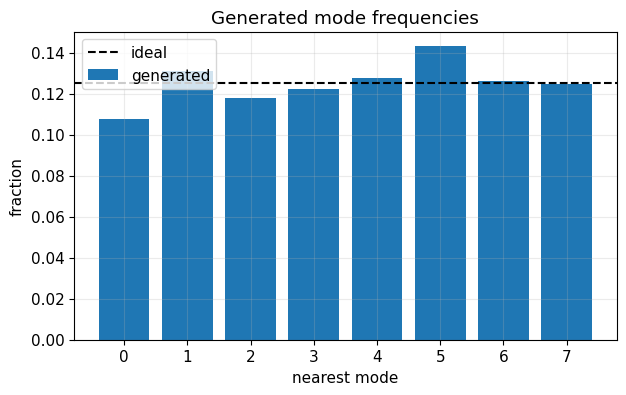

Mean absolute radial error: 0.237
Fraction >3σ from every mode: 2.0%
Modes receiving at least 1% of samples: 8/8
Total variation from uniform mode frequencies: 0.028


In [14]:
angles = 2 * torch.pi * torch.arange(N_MODES) / N_MODES
centers = RADIUS * torch.stack([torch.cos(angles), torch.sin(angles)], 1)
nearest_distance, nearest_mode = torch.cdist(generated, centers).min(1)
frequencies = torch.bincount(nearest_mode, minlength=N_MODES) / len(generated)
radial_error = (generated.norm(dim=1) - RADIUS).abs().mean()
gap_rate = (nearest_distance > 3 * DATA_STD).float().mean()
uniform = torch.full_like(frequencies, 1 / N_MODES)
mode_total_variation = 0.5 * (frequencies - uniform).abs().sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(N_MODES), frequencies.numpy(), label="generated")
ax.axhline(1 / N_MODES, color=PLOT_GUIDE_COLOR, linestyle="--", label="ideal")
ax.set(
    xlabel="nearest mode",
    ylabel="fraction",
    title="Generated mode frequencies",
    xticks=range(N_MODES),
)
ax.legend()
plt.show()
print(f"Mean absolute radial error: {radial_error:.3f}")
print(f"Fraction >3σ from every mode: {gap_rate:.1%}")
print(
    f"Modes receiving at least 1% of samples: {(frequencies > .01).sum().item()}/{N_MODES}"
)
print(f"Total variation from uniform mode frequencies: {mode_total_variation:.3f}")

## 14. From 2D points to MNIST

The mathematics remains unchanged, but the noise predictor becomes an image-to-image network:

- a U-Net predicts a noise image with the same shape as its input;
- time embeddings are injected into residual blocks;
- convolution and attention capture local and global image structure;
- training still samples a clean image, a time step, and Gaussian noise;
- generation still starts from Gaussian noise and iteratively denoises.

MNIST is an ideal next step because intermediate noisy and denoised images are intuitive. A small U-Net can train quickly, although iterative sampling remains slower than one-pass GAN or VAE generation.

## 15. Takeaways and homework experiments

### Takeaways
- The forward process is fixed and has a closed-form marginal $q(x_t\mid x_0)$.
- One time-conditioned network learns denoising tasks at every noise level.
- Noise prediction, clean-data prediction, and score estimation are equivalent parameterizations.
- Training uses random individual time steps and is parallel. Generation is iterative and sequential in time.
- Diffusion models generally offer stable regression training and strong mode coverage, at the cost of slow sampling.
- The noise schedule determines the signal-to-noise levels the model must learn.

### Mini-experiment 1 — Reduce `T` while keeping the schedule shape
- **Hypothesis:** Fewer reverse steps reduce sampling cost but make each denoising transition harder, degrading mode fidelity or coverage below some step count.
- **Metric/plot:** Report wall-clock sampling time, mode frequencies, radial error, and off-mode fraction. Compare reverse snapshots for the baseline and one reduced `T`.
- **Controls:** Preserve the cosine schedule shape over the shortened horizon, architecture, data, seed, optimizer, epochs, and number of generated samples.
- **Interpretation:** A speed–quality trade-off supports the discretization explanation. Unchanged quality indicates the original horizon was more than this toy problem needs.

### Mini-experiment 2 — Plot unnormalized score magnitudes and directions
- **Hypothesis:** Score magnitudes are larger near sharp low-noise mode boundaries and become smoother/weaker at high noise, information that is hidden by normalized arrows.
- **Metric/plot:** For the existing trained model, use shared color limits per comparison to plot $\|s_\theta(x_t,t)\|$ behind unnormalized quivers at the current probe times.
- **Controls:** Reuse the checkpoint in memory, identical grid and time indices, and the same conversion from predicted noise to score. Change only the visualization.
- **Interpretation:** Direction shows where density increases, while magnitude shows how strongly. Extreme high-noise magnitudes may also reveal scaling or approximation errors. 

### Extensions
- Replace the cosine schedule with a linear beta schedule.
- Remove the time embedding. The network cannot know then how aggressively to denoise.
- Train only on a restricted range of time steps and inspect failure elsewhere.

## Exit ticket

1. Write the closed-form forward corruption $q(x_t\mid x_0)$ and explain the roles of $\bar\alpha_t$ and $1-\bar\alpha_t$.
2. Relate noise prediction to clean-data prediction and score estimation.
3. Why can training process random time steps in parallel while generation must traverse time sequentially, and what does this imply for sampling cost?

<details>
<summary><strong>Self-check answers</strong></summary>

1. $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$: the first coefficient retains signal and the second sets accumulated noise variance.
2. From $\epsilon_\theta$, compute $\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta)/\sqrt{\bar\alpha_t}$ and $s_\theta\approx-\epsilon_\theta/\sqrt{1-\bar\alpha_t}$.
3. Training has both $x_0$ and a sampled $t$, so examples/noise levels form independent regression targets. Generation only has $x_t$ and must produce $x_{t-1}$ before the next transition, making sampling iterative and slower than one-pass generators.

</details>

## References and further reading

- [Ho, Jain & Abbeel, *Denoising Diffusion Probabilistic Models* (NeurIPS 2020)](https://proceedings.neurips.cc/paper/2020/hash/4c5bcfec8584af0d967f1ab10179ca4b-Abstract.html): Introduces the noise-prediction objective and ancestral DDPM sampler implemented here.
- [Luo, *Understanding Diffusion Models: A Unified Perspective* (arXiv:2208.11970)](https://arxiv.org/abs/2208.11970): Provides an accessible derivation connecting denoising, variational training, and score-based interpretations.